# B2a — So sánh model dự báo G và COGS theo ngày

Notebook chứng minh cho [hợp đồng dự báo](../../docs/hop_dong_du_bao.md) (PM chốt ngày 2026-10-14) và [kế hoạch AI GĐ2](../../docs/ke_hoach_ai_gd2.md).
Chủ notebook: myuyen (`README.md`). Chạy với thư mục làm việc = root repo.

**Notebook làm gì.** Dự báo G (doanh thu gộp, gồm cả đơn hủy) và COGS cho từng ngày, rồi chấm bằng **backtest**:
giả vờ đang đứng ở một ngày trong quá khứ (gọi là *origin*), dự báo 548 ngày tiếp theo, rồi so với số thật.
Làm ba lần với ba origin khác nhau; mỗi lần là một **fold**.

**Thuật ngữ dùng trong notebook:**
- **MAE** (sai số tuyệt đối trung bình): trung bình mỗi ngày dự báo lệch bao nhiêu đồng. Càng nhỏ càng tốt.
- **Điểm ngày kết hợp** = (MAE của G + MAE của COGS) / 2. Đây là thước chọn model (Q1).
- **RMSE**: giống MAE nhưng phạt nặng các ngày lệch nhiều. **R²**: phần biến động theo ngày mà dự báo giải thích được (1 là hoàn hảo).
- **Ứng viên** = (model, cửa sổ train, cách tính COGS). **Mốc** = cách dự báo đơn giản mà ứng viên phải thắng.

**Thứ tự các phần là cố ý** (đăng ký trước): bằng chứng cho biến lịch (§2) và luật chọn (§3) đứng trước mọi cell chấm điểm (§5 trở đi).

Đọc: `data/sales.csv`, `data/promotions.csv`. Ghi: `data/submission_b2.csv`, `data/forecast_b2_candidates.csv` (không commit, `CLAUDE.md` §2).

In [1]:
import pandas as pd, numpy as np
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

DATA = 'data'
R = lambda f, **k: pd.read_csv(f'{DATA}/{f}', low_memory=False, **k)

import hashlib, inspect, platform, time
import statsmodels, lightgbm as lgb, holidays
import matplotlib.pyplot as plt
from scripts.forecast import core as F     # code model dùng chung với stage dự báo của pipeline (scripts/forecast/stage.py)

print('python', platform.python_version(), '| pandas', pd.__version__, '| numpy', np.__version__,
      '| statsmodels', statsmodels.__version__, '| lightgbm', lgb.__version__, '| holidays', holidays.__version__)
print('sha256 sales.csv (12 ký tự đầu):', hashlib.sha256(open(f'{DATA}/sales.csv', 'rb').read()).hexdigest()[:12])
T_START = time.time()

python 3.13.5 | pandas 3.0.5 | numpy 2.5.1 | statsmodels 0.15.0 | lightgbm 4.7.0 | holidays 0.106
sha256 sales.csv (12 ký tự đầu): 081d539f50d4


## 1. Điều kiện tiên quyết

Hợp đồng §5: phải có đủ 3.833 ngày liên tục, và G > 0, COGS > 0 mọi ngày (cần cho phép log).

In [2]:
# Đọc dạng chuỗi rồi đổi kiểu bằng F.load_sales: stage pipeline đọc parquet của snapshot (cũng là chuỗi) qua cùng hàm,
# nên hai nơi có cùng số thực tới từng bit.
sales = F.load_sales(R('sales.csv', dtype=str))
info = F.check_prerequisites(sales)          # dừng (ValueError) nếu thiếu ngày hoặc có G, COGS ≤ 0
print('số ngày:', info['so_ngay'], '| từ', info['tu'], 'đến', info['den'])
print('liên tục, không thiếu ngày:', info['lien_tuc'])
print('G > 0 mọi ngày:', info['g_duong'], '| COGS > 0 mọi ngày:', info['cogs_duong'])
assert info['so_ngay'] == 3833
LAST = sales.index.max()

số ngày: 3833 | từ 2012-07-04 đến 2022-12-31
liên tục, không thiếu ngày: True
G > 0 mọi ngày: True | COGS > 0 mọi ngày: True


## 2. Bằng chứng cho biến lịch

Mọi bảng phụ dừng ở 2022-12-31, nên biến dự báo chỉ được suy từ lịch (`CLAUDE.md` §5).
Mỗi biến ngoài các kết luận đã chứng minh ở `CLAUDE.md` §5 phải có bằng chứng ở đây, **trước** khi chấm điểm.

### 2.1 Mốc chế độ sau đứt gãy (Q4)

`CLAUDE.md` §5.2 ghi đứt gãy "cuối 2018". PM chốt mốc 2019-01-01 với điều kiện cell này xác nhận:
năm có G trung bình ngày giảm mạnh nhất so với năm trước phải là 2019.

In [3]:
promo = F.load_promotions(R('promotions.csv', dtype=str))
cal = F.Calendar(sales, promo)   # dừng (ValueError) nếu năm giảm mạnh nhất không phải 2019 (Q4)
display(cal.regime_table.round({'G_tb_ngay': 0, 'COGS_tb_ngay': 0}))
print('Năm G trung bình ngày giảm mạnh nhất:', cal.biggest_drop_year, '| mốc chế độ dùng trong model:', F.REGIME_START.date())

,so_ngay,G_tb_ngay,COGS_tb_ngay,G_doi_so_nam_truoc_%
Date,,,,
2012,181,4096673.0,3245646.0,NaN
2013,365,4540190.0,4016384.0,10.8
2014,365,5128345.0,4313993.0,13.0
2015,365,5177901.0,4562854.0,1.0
2016,366,5750384.0,4864916.0,11.1
2017,365,5236067.0,4642153.0,-8.9
2018,365,5068829.0,4225139.0,-3.2
2019,365,3114524.0,2753981.0,-38.6
2020,366,2881181.0,2420998.0,-7.5


Năm G trung bình ngày giảm mạnh nhất: 2019 | mốc chế độ dùng trong model: 2019-01-01


### 2.2 Lịch khuyến mãi lặp theo ngày dương lịch (Q3)

Câu hỏi: mỗi đợt khuyến mãi có chạy vào **cùng ngày dương lịch** mỗi năm không? Nếu có, ta đặt được cờ khuyến mãi cho 2023–2024,
dù `promotions.csv` dừng ở 2022.

**Luật lặp:** mỗi họ khuyến mãi lấy ngày bắt đầu và ngày kết thúc (tháng-ngày) hay gặp nhất; họ chỉ xuất hiện ở năm lẻ thì chỉ lặp ở năm lẻ;
chỉ áp từ năm đầu tiên họ đó có trong bảng. Cell dưới kiểm luật này tái tạo các cửa sổ thật 2013–2022 sát tới đâu.
Phần 2023–2024 là **ngoại suy** từ luật, không có trong dữ liệu.

In [4]:
tt = cal.rule_check            # luật lặp của từng họ khuyến mãi (F.Calendar) và độ lệch so với promotions.csv
display(tt)
print('Lệch lớn nhất ở ngày đầu hoặc ngày cuối (ngày):', int(max(tt.lech_dau_toi_da.max(), tt.lech_cuoi_toi_da.max())))
print('Tỷ lệ ngày lệch trên toàn bộ ngày khuyến mãi 2013–2022: %.2f%%' % (tt.so_ngay_lech.sum() / tt.so_ngay_that.sum() * 100))

,start_md,end_md,first_year,odd_only,so_nam,lech_dau_toi_da,lech_cuoi_toi_da,so_ngay_that,so_ngay_lech,ty_le_ngay_lech_%
family,,,,,,,,,,
Fall Launch,08-30,10-01,2013,False,10,1,1,332,4,1.20
Mid-Year Sale,06-23,07-22,2013,False,10,0,0,300,0,0.00
Rural Special,01-30,03-01,2013,True,5,1,0,154,1,0.65
Spring Sale,03-18,04-17,2013,False,10,0,0,310,0,0.00
Urban Blowout,07-30,09-02,2013,True,5,0,0,175,0,0.00
Year-End Sale,11-18,01-02,2013,False,10,1,2,456,4,0.88


Lệch lớn nhất ở ngày đầu hoặc ngày cuối (ngày): 2
Tỷ lệ ngày lệch trên toàn bộ ngày khuyến mãi 2013–2022: 0.52%


**Đọc kết quả §2.2.** Cả 6 họ khuyến mãi lặp lại theo ngày dương lịch. Luật lặp lệch tối đa 2 ngày ở ngày đầu hoặc ngày cuối,
và chỉ 0,52% số ngày khuyến mãi 2013–2022 bị xếp sai. Urban Blowout và Rural Special chỉ có ở năm lẻ.
→ Dùng cờ của cả 6 họ. Năm 2023 (lẻ) có cả Rural Special (30/01 → 01/03) và Urban Blowout (30/07 → 02/09).

### 2.3 Tết và đầu tháng: có hiệu ứng ngoài các biến đã có không?

Hai nhóm biến này chưa có kết luận trong `CLAUDE.md` §5. Lời giải tham khảo dùng cả hai (theo tài liệu, Mục XIV.3), nhưng ta phải tự kiểm.

**Cách kiểm.** Hồi quy log G trên các biến đã có (mùa vụ năm, cuối tháng, cờ khuyến mãi, chế độ), **không** có Tết và đầu tháng.
Phần dư (phần model chưa giải thích) được gom theo khoảng cách tới mồng 1 Tết (nhóm 7 ngày), và theo ngày 1–3 của tháng.

**Luật đưa biến vào (viết trước khi xem kết quả):** dùng nhóm biến nếu có ít nhất một nhóm có phần dư trung bình
|≥ 0,05| trên thang log (khoảng 5%) **và** cùng dấu ở ít nhất 75% số năm.

Ngày Tết lấy từ thư viện `holidays` (không gõ tay), đối chiếu với hai ngày lời giải tham khảo ghi: 22/01/2023 và 10/02/2024.

In [5]:
# Hồi quy, gom phần dư và luật đưa biến nằm trong F.Calendar (_evidence); ngưỡng: F.EVIDENCE_MIN_RESID, F.EVIDENCE_MIN_SHARE
print('Ngày mồng 1 Tết:', {y: str(d.date()) for y, d in sorted(cal.tet.items()) if 2012 <= y <= 2024})
print('Tết (nhóm 7 ngày, số đầu nhóm = số ngày từ mồng 1)', '→ dùng' if cal.use_tet else '→ không dùng')
display(cal.tet_evidence.round(3))
print('Đầu tháng (ngày 1, 2, 3)', '→ dùng' if cal.use_first else '→ không dùng')
display(cal.first_evidence.round(3))
USE_TET, USE_FIRST = cal.use_tet, cal.use_first

Ngày mồng 1 Tết: {2012: '2012-01-23', 2013: '2013-02-10', 2014: '2014-01-31', 2015: '2015-02-19', 2016: '2016-02-08', 2017: '2017-01-28', 2018: '2018-02-16', 2019: '2019-02-05', 2020: '2020-01-25', 2021: '2021-02-12', 2022: '2022-02-01', 2023: '2023-01-22', 2024: '2024-02-10'}
Tết (nhóm 7 ngày, số đầu nhóm = số ngày từ mồng 1) → không dùng


,phan_du_tb,so_ngay,ty_le_nam_cung_dau,dat_luat
nhom,,,,
-35.0,0.027,77,0.5,False
-28.0,-0.034,77,0.6,False
-21.0,-0.044,70,0.5,False
-14.0,-0.019,70,0.6,False
-7.0,0.009,70,0.5,False
0.0,0.090,70,0.7,False
7.0,0.040,70,0.6,False
14.0,-0.038,70,0.4,False
21.0,-0.081,70,0.6,False


Đầu tháng (ngày 1, 2, 3) → dùng


,phan_du_tb,so_ngay,ty_le_nam_cung_dau,dat_luat
nhom,,,,
1.0,0.592,125,1.000,True
2.0,0.165,125,0.909,True
3.0,0.025,125,0.727,False


**Đọc kết quả §2.3.**
- **Tết: không dùng.** Sau khi đã có mùa vụ năm, cờ khuyến mãi và cuối tháng, không nhóm 7 ngày nào quanh Tết đạt luật
  (nhóm mồng 1 → mồng 7 có phần dư dương rõ nhất nhưng chỉ cùng dấu ở 70% số năm, dưới ngưỡng 75%). Nhóm "35" chỉ có 10 ngày nên không đáng tin.
- **Đầu tháng: dùng.** Ngày 1 cao hơn hẳn phần model chưa có biến này giải thích, cùng dấu ở **mọi** năm; ngày 2 cũng đạt luật.
  Đây là phát hiện mới: `CLAUDE.md` §5.4 chỉ nói dốc tăng về cuối tháng.

### 2.4 Tỷ lệ COGS/G tháng 8 năm lẻ: 1,34 hay 1,36?

Hợp đồng §10: `CLAUDE.md` §5.6 ghi khoảng 1,36, `problem_statement.md` ghi 1,34. Cell dưới tính theo hai cách
để xem lệch có phải do cách tính: **tỷ lệ của tổng** (ΣCOGS/ΣG của tháng) và **trung bình tỷ lệ ngày**.

In [6]:
aug = sales[(sales.index.month == 8) & (sales.index.year % 2 == 1)]
t = aug.groupby(aug.index.year).agg(G=('Revenue', 'sum'), COGS=('COGS', 'sum'))
t['ty_le_cua_tong'] = t['COGS'] / t['G']
t['tb_ty_le_ngay'] = (aug['COGS'] / aug['Revenue']).groupby(aug.index.year).mean()
display(t[['ty_le_cua_tong', 'tb_ty_le_ngay']].round(4))
print('Gộp mọi tháng 8 năm lẻ — tỷ lệ của tổng: %.4f | trung bình tỷ lệ ngày: %.4f'
      % (aug['COGS'].sum() / aug['Revenue'].sum(), (aug['COGS'] / aug['Revenue']).mean()))
print('Trung bình các tỷ lệ của tổng theo năm: %.4f' % t['ty_le_cua_tong'].mean())

,ty_le_cua_tong,tb_ty_le_ngay
Date,,
2013,1.3068,1.3241
2015,1.3235,1.3502
2017,1.3539,1.3617
2019,1.3424,1.3582
2021,1.4009,1.4232


Gộp mọi tháng 8 năm lẻ — tỷ lệ của tổng: 1.3403 | trung bình tỷ lệ ngày: 1.3635
Trung bình các tỷ lệ của tổng theo năm: 1.3455


**Đọc kết quả §2.4.** Hai con số trong tài liệu đều đúng, chỉ khác cách tính trên cùng các tháng 8 năm lẻ 2013–2021:
**tỷ lệ của tổng** (ΣCOGS/ΣG) ≈ 1,34, như `problem_statement.md`; **trung bình tỷ lệ ngày** ≈ 1,36, như `CLAUDE.md` §5.6.
Hợp đồng dùng tỷ lệ của tổng (§2.2 hợp đồng: tỷ lệ phải tính lại từ tử và mẫu).

## 3. Đăng ký trước: ứng viên, tham số, luật chọn

Cell này chạy **trước** mọi cell chấm điểm, và không được sửa sau khi đã xem điểm. Nội dung khớp hợp đồng §0, §4, §5.

| Thành phần | Giá trị |
|---|---|
| Fold (origin) | F1 2020-06-30, F2 2020-12-31, F3 2021-06-30; mỗi fold dự báo 548 ngày |
| Mốc | `naive1y`, `naive2y` (mốc sàn), `baseline_cu` (tái tạo cách của `baseline.ipynb`) |
| Model | `arima_2019` (Should), `sarimax_2019`, `sarimax_full`, `lgbm_2019`, `lgbm_full`, `blend_full` |
| Cách COGS | `ratio` (G × hồ sơ tỷ lệ tháng × Urban Blowout), `direct` (cùng model train trên log COGS) |
| Thước chọn | Điểm ngày kết hợp = (MAE G + MAE COGS) / 2, trung bình ba fold |
| Luật | 1) thắng `naive2y` ở cả ba fold; 2) điểm thấp nhất; 3) trong vòng 1% thì chọn đơn giản hơn |
| Thứ tự đơn giản | theo danh sách model ở trên, rồi `ratio` trước `direct` |
| Bản gộp | `w × lgbm_full + (1 − w) × sarimax_full`, w ∈ {0; 0,25; 0,5; 0,75; 1}, chọn trên năm cuối của phần train |

Từ 2026-10-15, tham số, ứng viên và luật nằm trong `scripts/forecast/core.py`; stage dự báo của pipeline dùng đúng module này,
nên notebook và pipeline ra cùng số. Cell dưới in lại các hằng số và mã của hàm `select` để đối chiếu. Tham số cố định, không dò trên vùng chấm.

In [7]:
# Tham số, ứng viên và luật chọn nằm trong scripts/forecast/core.py (đăng ký 2026-10-14). Stage pipeline dùng đúng các hằng số này.
print('Fold:', {f: str(o.date()) for f, o in F.FOLDS.items()}, '| H =', F.H, '| ngưỡng hòa:', F.TIE, '| lưới trọng số gộp:', F.BLEND_GRID)
print('SARIMAX', F.SARIMAX_ORDER, '| ARIMA', F.ARIMA_ORDER, '| vòng tối ưu tối đa', F.MAXITER, '| LightGBM', F.LGB_ROUNDS, 'vòng,', F.LGB_PARAMS)
print('Số ứng viên:', len(F.CANDIDATES), '| mốc:', F.BASELINES, '| mốc sàn:', F.FLOOR)
for f, o in F.FOLDS.items():
    print(f, 'origin', o.date(), '→ vùng chấm', (o + pd.Timedelta(days=1)).date(), '→', (o + pd.Timedelta(days=F.H)).date())
print()
print(inspect.getsource(F.select))   # luật chọn, đúng hàm stage pipeline gọi

Fold: {'F1': '2020-06-30', 'F2': '2020-12-31', 'F3': '2021-06-30'} | H = 548 | ngưỡng hòa: 0.01 | lưới trọng số gộp: [0.0, 0.25, 0.5, 0.75, 1.0]
SARIMAX (1, 0, 1) | ARIMA (1, 1, 1) | vòng tối ưu tối đa 1000 | LightGBM 800 vòng, {'objective': 'regression', 'learning_rate': 0.03, 'num_leaves': 15, 'min_data_in_leaf': 20, 'feature_fraction': 0.9, 'lambda_l2': 1.0, 'num_threads': 4, 'seed': 42, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
Số ứng viên: 12 | mốc: ['naive1y', 'naive2y', 'baseline_cu'] | mốc sàn: naive2y
F1 origin 2020-06-30 → vùng chấm 2020-07-01 → 2021-12-30
F2 origin 2020-12-31 → vùng chấm 2021-01-01 → 2022-07-02
F3 origin 2021-06-30 → vùng chấm 2021-07-01 → 2022-12-30

def select(scores):
    """scores: DataFrame cột model, cogs_method, fold, score. Trả bảng xếp hạng và ứng viên is_primary theo luật §5."""
    floor = scores[scores.model == FLOOR].set_index('fold')['score']
    rows = []
    for (m, c), g in scores[scores.model.isin(MODELS)].groupby(['mode

## 4. Biến lịch, mốc và model

- **Biến cho model tuyến tính** (log + SARIMAX): mùa vụ năm (Fourier 5 cặp), khoảng cách tới cuối tháng, cờ 3 ngày cuối tháng,
  cờ từng đợt khuyến mãi theo luật lặp (§2.2), cờ chế độ (chỉ ở cửa sổ toàn chuỗi), và Tết, đầu tháng nếu §2.3 cho dùng.
- **Biến cho LightGBM:** như trên, thêm tháng, ngày trong tháng, ngày trong năm, năm chẵn/lẻ, số ngày từ đầu đợt khuyến mãi,
  và số ngày tới Tết nếu §2.3 cho dùng. **Không** có biến "năm" dạng số, **không** có thứ trong tuần (`CLAUDE.md` §5.5).
- Model train trên log; đổi ngược bằng exp cho ra trung vị, là dự báo đúng cho thước MAE (hợp đồng §5).
- Code: `F.Calendar` (biến lịch), `F.Forecaster` (mốc, model, bản gộp) trong `scripts/forecast/core.py`.

In [8]:
fc = F.Forecaster(sales, cal)    # mốc: F.Forecaster.baseline; model: F.Forecaster.model_log_forecast; bản gộp: F.Forecaster.candidate
print('Biến cho log + SARIMAX (toàn chuỗi):', list(cal.features(sales.index[:5], 'linear', 'full').columns))
print('Biến cho LightGBM (toàn chuỗi):', list(cal.features(sales.index[:5], 'tree', 'full').columns))

Biến cho log + SARIMAX (toàn chuỗi): ['sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3', 'sin4', 'cos4', 'sin5', 'cos5', 'days_to_eom', 'is_last1', 'is_last2', 'is_last3', 'promo_fall_launch', 'promo_mid_year_sale', 'promo_rural_special', 'promo_spring_sale', 'promo_urban_blowout', 'promo_year_end_sale', 'post2019', 'is_first1', 'is_first2', 'is_first3']
Biến cho LightGBM (toàn chuỗi): ['sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3', 'sin4', 'cos4', 'sin5', 'cos5', 'days_to_eom', 'is_last1', 'is_last2', 'is_last3', 'promo_fall_launch', 'promo_mid_year_sale', 'promo_rural_special', 'promo_spring_sale', 'promo_urban_blowout', 'promo_year_end_sale', 'post2019', 'is_first1', 'is_first2', 'is_first3', 'month', 'dom', 'doy', 'is_odd_year', 'promo_fall_launch_since', 'promo_mid_year_sale_since', 'promo_rural_special_since', 'promo_spring_sale_since', 'promo_urban_blowout_since', 'promo_year_end_sale_since']


## 5. Backtest: chạy mọi ứng viên và mốc trên ba fold

Chạy lâu nhất notebook (khoảng nửa giờ: mỗi fold train lại mọi model). Kết quả ngày lưu trong `pred`, một dòng = ngày × ứng viên × fold.

**Ghi chú lần chạy 1 (2026-10-14).** Lần chạy đầu, bộ tối ưu của log + SARIMAX **không hội tụ** ở mọi lần fit
(statsmodels báo `ConvergenceWarning`): hệ số ước lượng ra chưa phải nghiệm của model đã đăng ký, nên điểm của log + SARIMAX
và của bản gộp lần đó không dùng được. Ứng viên `is_primary` lần đó là `lgbm_full / direct`.
Sửa phần kỹ thuật của bộ tối ưu, áp cho **mọi** lần fit (backtest, chọn trọng số gộp, bản cuối): bộ tối ưu xuất phát từ nghiệm
hồi quy thường (OLS) trên cùng biến, tối đa 1.000 vòng; lần nào L-BFGS chưa báo hội tụ thì chạy Powell rồi L-BFGS lại (cột `du_phong`).
Ứng viên, biến, bậc ARMA, lưới trọng số, ngưỡng và luật chọn **giữ nguyên** như §3.
Hằng số của hồi quy chuyển từ tham số `trend` sang một cột hằng trong biến ngoại sinh; hai cách viết là cùng một model.
Cảnh báo `ConvergenceWarning` vẫn có thể in ra ở lần fit phải dùng dự phòng: bảng hội tụ ngay sau backtest ghi trạng thái **cuối cùng** của từng lần fit.
Kết quả dưới đây là lần chạy 2, là kết quả chính thức. Cell ngay sau backtest liệt kê trạng thái hội tụ của từng lần fit.

In [9]:
pred, weights = F.backtest(fc, progress=print)
print('Trọng số LightGBM trong bản gộp, theo (fold, cách COGS):', weights)

D:\retail-analytics\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


F1 xong sau 60 giây


F2 xong sau 128 giây


F3 xong sau 215 giây
Trọng số LightGBM trong bản gộp, theo (fold, cách COGS): {('F1', 'ratio'): 0.0, ('F1', 'direct'): 0.0, ('F2', 'ratio'): 0.5, ('F2', 'direct'): 0.5, ('F3', 'ratio'): 0.75, ('F3', 'direct'): 0.75}


In [10]:
fits = F.check_convergence(fc.fit_log)       # dừng (ValueError) nếu có lần fit không hội tụ
print('Số lần fit ARIMA/SARIMAX:', len(fits), '| không hội tụ:', int((~fits.hoi_tu).sum()), '| tổng thời gian fit: %d giây' % fits.giay.sum())
display(fits.groupby(['model', 'target']).agg(so_lan=('hoi_tu', 'size'), hoi_tu=('hoi_tu', 'all'), so_lan_du_phong=('du_phong', 'sum'),
                                              giay_tb=('giay', 'mean')).round(0))

Số lần fit ARIMA/SARIMAX: 24 | không hội tụ: 0 | tổng thời gian fit: 197 giây


so_lan  hoi_tu  so_lan_du_phong  giay_tb
model        target                                           
arima_2019   COGS          3    True                0      0.0
             Revenue       3    True                0      0.0
sarimax_2019 COGS          3    True                0      5.0
             Revenue       3    True                0      5.0
sarimax_full COGS          6    True                1     16.0
             Revenue       6    True                0     12.0

In [11]:
bt = F.score_table(pred)       # MAE, RMSE, R² theo ngày trên G và COGS; score = (MAE G + MAE COGS) / 2
wide = bt.pivot_table(index=['model', 'cogs_method'], columns='fold', values='score')
wide['tb_3_fold'] = wide.mean(axis=1)
print('Điểm ngày kết hợp theo fold (đồng; càng nhỏ càng tốt):')
display(wide.sort_values('tb_3_fold').round(0))

Điểm ngày kết hợp theo fold (đồng; càng nhỏ càng tốt):


fold                             F1         F2         F3  tb_3_fold
model        cogs_method                                            
lgbm_full    direct        523254.0   634282.0   573944.0   577160.0
             ratio         539085.0   635811.0   577685.0   584193.0
blend_full   direct        569725.0   618349.0   566154.0   584743.0
             ratio         576605.0   621230.0   571764.0   589866.0
baseline_cu  copy          487406.0   661311.0   681962.0   610226.0
sarimax_full direct        569725.0   660567.0   621779.0   617357.0
             ratio         576605.0   666247.0   631445.0   624765.0
lgbm_2019    direct        613041.0   729686.0   626455.0   656394.0
sarimax_2019 direct        622364.0   708413.0   639543.0   656773.0
lgbm_2019    ratio         616864.0   731087.0   623864.0   657272.0
sarimax_2019 ratio         622190.0   708344.0   645536.0   658690.0
naive1y      copy          607459.0   711793.0   663727.0   660993.0
naive2y      copy          675499.0   785472.0   691691.0   717554.0
arima_2019   direct       1587336.0  1603412.0  1701418.0  1630722.0
             ratio        1679903.0  1646264.0  1755961.0  1694042.0

## 6. Áp luật chọn (hợp đồng §5)

Hàm `select` viết ở §3, trước khi có điểm. Cell này chỉ gọi nó.

In [12]:
ranking, PRIMARY, STEP = F.select(bt[['model', 'cogs_method', 'fold', 'score']])
display(ranking.round({'diem_tb': 0}))
print('Ứng viên is_primary:', PRIMARY, '| bước luật:', STEP)
best_floor = bt[bt.model == F.FLOOR].score.mean()
p_score = ranking.set_index(['model', 'cogs_method']).diem_tb.get(PRIMARY, best_floor)
print('Điểm trung bình — %s: %.0f | mốc %s: %.0f | giảm %.1f%% so với mốc' % (PRIMARY, p_score, F.FLOOR, best_floor, (1 - p_score / best_floor) * 100))

,model,cogs_method,diem_tb,so_fold_thang_san,qua_san
6,lgbm_full,direct,577160.0,3,True
7,lgbm_full,ratio,584193.0,3,True
2,blend_full,direct,584743.0,3,True
3,blend_full,ratio,589866.0,3,True
10,sarimax_full,direct,617357.0,3,True
11,sarimax_full,ratio,624765.0,3,True
4,lgbm_2019,direct,656394.0,3,True
8,sarimax_2019,direct,656773.0,3,True
5,lgbm_2019,ratio,657272.0,3,True
9,sarimax_2019,ratio,658690.0,3,True


Ứng viên is_primary: ('lgbm_full', 'direct') | bước luật: buoc_2_diem_thap_nhat
Điểm trung bình — ('lgbm_full', 'direct'): 577160 | mốc naive2y: 717554 | giảm 19.6% so với mốc


**Đọc kết quả §6.**
- **Ứng viên chính: `lgbm_full / direct`** — LightGBM, train trên toàn chuỗi kèm cờ chế độ, COGS dự báo trực tiếp. Chọn ở bước 2 (điểm thấp nhất).
- Mọi ứng viên trừ ARIMA thuần đều qua sàn ở cả ba fold. ARIMA thuần thua xa cả mốc: không có biến lịch thì dự báo 548 ngày gần như phẳng.
- Bản gộp `blend_full / direct` đứng thứ ba, sau hai biến thể LightGBM, và cao hơn điểm thấp nhất khoảng 1,3%: ngoài ngưỡng hòa 1%, nên không thay được LightGBM.
- Cửa sổ toàn chuỗi thắng cửa sổ từ 2019 ở cả LightGBM lẫn log + SARIMAX: dữ liệu trước đứt gãy vẫn có ích khi có cờ chế độ.
- **Điểm của ứng viên thắng là lạc quan** (hợp đồng §5 bước 5): nó được chọn từ 12 ứng viên trên cùng ba fold.

## 7. Chỉ số báo kèm

- RMSE, R² theo ngày trên G và COGS (cùng bộ thước cuộc thi, theo tài liệu tham khảo);
- MAPE trên G tháng (tháng đủ ngày trong vùng chấm) — chỉ số hiển thị cho người lập kế hoạch;
- tháng 8/2021 (năm lẻ): MAE G, tỷ lệ tái tạo biên độ sụt, tỷ lệ COGS/G dự báo so với thực tế (RQ3);
- coverage của khoảng 80%: quantile phần dư log lấy từ hai fold còn lại.

In [13]:
report = F.report_metrics(pred, bt, sales)   # MAPE G tháng, tháng 8/2021, coverage 80% (quantile từ hai fold còn lại)
cols = F.REPORT_COLS
report.to_csv(f'{DATA}/forecast_b2_backtest.csv', index=False)   # để đối chiếu với rpt_forecast_backtest của pipeline
summary = report.groupby(['model', 'cogs_method'])[cols].mean().sort_values('score')
print('Trung bình ba fold:')
display(summary.round(3))
print('Độ lệch log của ứng viên chính (trung bình log thực tế − log dự báo, > 0 là dự báo thấp):',
      round(pred[(pred.model == PRIMARY[0]) & (pred.cogs_method == PRIMARY[1])].logres.mean(), 4))

Trung bình ba fold:


score        mae_g     mae_cogs       rmse_g    rmse_cogs   r2_g  r2_cogs  mape_g_thang_%  mae_g_t8_2021  tai_tao_bien_do  cogs_g_t8_du_bao  cogs_g_t8_thuc  coverage_80  \
model        cogs_method                                                                                                                                                                                   
lgbm_full    direct        577159.922   609735.883   544583.961   824838.065   744828.863  0.742    0.725          11.399     510166.174            0.791             1.323           1.401        0.789   
             ratio         584193.468   609735.883   558651.054   824838.065   769117.676  0.742    0.706          11.399     510166.174            0.791             1.331           1.401        0.789   
blend_full   direct        584742.585   615356.412   554128.758   859788.332   781705.458  0.718    0.696           9.202     480267.120            0.873             1.289           1.401        0.785   
             ratio         589866.247   615356.412   564376.083   859788.332   803762.545  0.718    0.678           9.202     480267.120            0.873             1.331           1.401        0.785   
baseline_cu  copy          610226.442   628848.938   591603.947   882011.643   822328.900  0.702    0.659          13.183     691717.714            0.635             0.978           1.401        0.774   
sarimax_full direct        617356.977   651041.026   583672.927   936629.669   849939.322  0.667    0.641           8.163     519220.161            0.940             1.270           1.401        0.789   
             ratio         624765.311   651041.026   598489.595   936629.669   873806.298  0.667    0.620           8.163     519220.161            0.940             1.331           1.401        0.789   
lgbm_2019    direct        656393.877   699894.300   612893.454   973823.107   846611.935  0.640    0.645          12.182     600684.971            0.760             1.328           1.401        0.793   
sarimax_2019 direct        656773.112   695327.885   618218.340   980303.486   877420.024  0.635    0.618           9.825     606078.025            0.840             1.296           1.401        0.797   
lgbm_2019    ratio         657271.606   699894.300   614648.912   973823.107   860801.794  0.640    0.633          12.182     600684.971            0.760             1.342           1.401        0.793   
sarimax_2019 ratio         658690.092   695327.885   622052.298   980303.486   883118.854  0.635    0.613           9.825     606078.025            0.840             1.342           1.401        0.797   
naive1y      copy          660993.060   721311.155   600674.965  1006845.789   832041.931  0.615    0.657          12.413    1384399.195            0.251             0.983           1.401        0.795   
naive2y      copy          717553.830   759266.206   675841.453  1031203.694   916803.745  0.597    0.583          12.711     683198.195            0.754             1.342           1.401        0.791   
arima_2019   direct       1630722.119  1783702.112  1477742.126  2177952.639  1822205.207 -0.797   -0.644          60.304    1563070.133            0.365             0.893           1.401        0.611   
             ratio        1694042.468  1783702.112  1604382.825  2177952.639  1974375.954 -0.797   -0.935          60.304    1563070.133            0.365             1.342           1.401        0.611   

                          coverage_80_tu_nhien  
model        cogs_method                        
lgbm_full    direct                        NaN  
             ratio                         NaN  
blend_full   direct                        NaN  
             ratio                         NaN  
baseline_cu  copy                          NaN  
sarimax_full direct                      0.820  
             ratio                       0.820  
lgbm_2019    direct                        NaN  
sarimax_2019 direct                      0.797  
lgbm_2019    ratio      

Độ lệch log của ứng viên chính (trung bình log thực tế − log dự báo, > 0 là dự báo thấp): 0.0011


In [14]:
show = report[(report.model == PRIMARY[0]) & (report.cogs_method == PRIMARY[1]) | (report.model == F.FLOOR)]
print('Ứng viên chính và mốc sàn, theo từng fold:')
display(show[['model', 'cogs_method', 'fold'] + cols].round(3))

Ứng viên chính và mốc sàn, theo từng fold:


,model,cogs_method,fold,score,mae_g,mae_cogs,rmse_g,rmse_cogs,r2_g,r2_cogs,mape_g_thang_%,mae_g_t8_2021,tai_tao_bien_do,cogs_g_t8_du_bao,cogs_g_t8_thuc,coverage_80,coverage_80_tu_nhien
21,lgbm_full,direct,F1,523253.925,569340.907,477166.942,756917.176,641848.487,0.763,0.772,11.080,505440.698,0.804,1.338,1.401,0.790,NaN
22,lgbm_full,direct,F2,634281.651,667630.259,600933.042,902094.956,826599.468,0.738,0.713,12.020,510221.964,0.782,1.321,1.401,0.786,NaN
23,lgbm_full,direct,F3,573944.190,592236.481,555651.898,815502.062,766038.634,0.725,0.688,11.096,514835.860,0.786,1.309,1.401,0.790,NaN
30,naive2y,copy,F1,675498.735,731154.262,619843.208,972053.456,829440.061,0.609,0.620,13.972,683198.195,0.754,1.342,1.401,0.808,NaN
31,naive2y,copy,F2,785471.535,829820.408,741122.662,1123253.504,999692.325,0.594,0.581,13.353,683198.195,0.754,1.342,1.401,0.779,NaN
32,naive2y,copy,F3,691691.219,716823.949,666558.489,998304.121,921278.850,0.588,0.549,10.807,683198.195,0.754,1.342,1.401,0.785,NaN


**Đọc kết quả §7.**
- **COGS trực tiếp có MAE COGS thấp hơn COGS qua hồ sơ tỷ lệ ở mọi model** (cột `mae_cogs`), nhưng chênh lệch nhỏ:
  với LightGBM toàn chuỗi, điểm kết hợp của hai cách chỉ cách nhau khoảng 1,2%.
  Đây **chưa** phải bằng chứng rằng mô hình hóa COGS như tỷ lệ là sai (`CLAUDE.md` §5.7): hồ sơ tỷ lệ đã đăng ký chỉ theo (tháng × Urban Blowout),
  không biết các đợt khuyến mãi khác, trong khi cell §8 cho thấy COGS/G > 1 cả ở đợt Year-End. Model trực tiếp có đủ cờ khuyến mãi.
  Hồ sơ tỷ lệ theo mọi đợt khuyến mãi **chưa được thử**; thêm nó sau khi đã xem điểm là chọn theo kết quả, nên để làm hướng mở rộng.
- **Thước ngày và thước tháng không cùng thứ hạng.** LightGBM có điểm ngày tốt nhất, nhưng log + SARIMAX toàn chuỗi và bản gộp có MAPE G tháng thấp hơn,
  và tái tạo biên độ sụt tháng 8/2021 đầy đủ hơn. Thước chọn đã chốt là điểm ngày (Q1), nên kết quả chọn không đổi; báo cáo cần nêu điểm này.
- **Tháng 8 năm lẻ (RQ3):** ứng viên chính tái tạo khoảng 79% biên độ sụt, và dự báo COGS/G tháng 8/2021 thấp hơn thực tế. Đúng chiều H5.3 (tái tạo thiếu).
- **Khoảng 80%:** coverage của ứng viên chính sát 80% ở cả ba fold. Khoảng tự nhiên của log + SARIMAX cũng gần 80% sau khi sửa bộ tối ưu.
- Độ lệch log của ứng viên chính gần 0, nên không cần hiệu chỉnh.

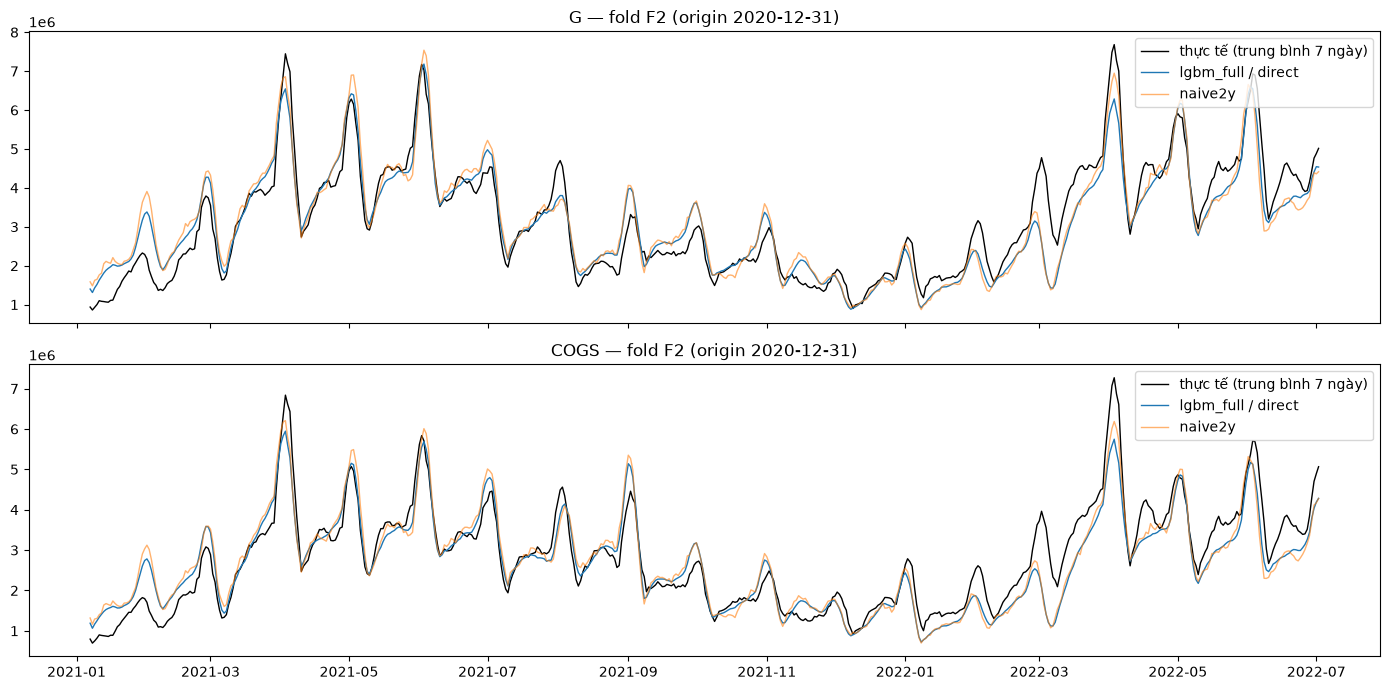

In [15]:
f2 = pred[(pred.fold == 'F2')]
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for a, (col, hat, title) in zip(ax, (('G', 'G_hat', 'G'), ('C', 'C_hat', 'COGS'))):
    base = f2[f2.model == F.FLOOR].set_index('date')
    prim = f2[(f2.model == PRIMARY[0]) & (f2.cogs_method == PRIMARY[1])].set_index('date')
    a.plot(base.index, base[col].rolling(7).mean(), lw=1, color='black', label='thực tế (trung bình 7 ngày)')
    a.plot(prim.index, prim[hat].rolling(7).mean(), lw=1, label=f'{PRIMARY[0]} / {PRIMARY[1]}')
    a.plot(base.index, base[hat].rolling(7).mean(), lw=1, alpha=0.6, label=F.FLOOR)
    a.set_title(f'{title} — fold F2 (origin 2020-12-31)'); a.legend(loc='upper right')
plt.tight_layout(); plt.show()

## 8. Bản cuối: train tới 2022-12-31, dự báo 2023-01-01 → 2024-07-01

Mọi ứng viên và mốc đều được dự báo (stage pipeline sau này ghi tất cả vào `rpt_forecast_daily`; hợp đồng §7).
Khoảng 80% lấy quantile phần dư log từ cả ba fold. File nộp lấy từ ứng viên `is_primary`.

In [16]:
sub = R('sample_submission.csv', parse_dates=['Date'])
dates = pd.DatetimeIndex(sub['Date'])
assert len(dates) == F.H and dates.min() == pd.Timestamp('2023-01-01') and dates.max() == pd.Timestamp('2024-07-01')
final, final_w = F.final_forecast(fc, pred, PRIMARY, STEP, dates)   # mọi mốc và ứng viên, train tới ngày thực tế cuối
print('Trọng số LightGBM của bản gộp bản cuối:', final_w)
fits = F.check_convergence(fc.fit_log)
print('Mọi lần fit ARIMA/SARIMAX (backtest + bản cuối):', len(fits), '| không hội tụ:', int((~fits.hoi_tu).sum()))

D:\retail-analytics\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Trọng số LightGBM của bản gộp bản cuối: {'ratio': 1.0, 'direct': 1.0}
Mọi lần fit ARIMA/SARIMAX (backtest + bản cuối): 32 | không hội tụ: 0


**Kiểm tháng 8/2023** (hợp đồng §9): G tháng 8/2023 dự báo phải thấp hơn G thực tế tháng 8/2022, và COGS/G tháng 8/2023 > 1.

In [17]:
a23 = F.august_2023_check(final, sales, PRIMARY)   # dừng (ValueError) nếu ứng viên chính không đạt
display(a23[['G_t8_2023_so_voi_t8_2022', 'cogs_g_t8_2023', 'dat']].round(3))

G_t8_2023_so_voi_t8_2022  cogs_g_t8_2023    dat
model        cogs_method                                                 
arima_2019   direct                          0.508           0.986  False
             ratio                           0.508           1.369   True
baseline_cu  copy                            0.873           1.000   True
blend_full   direct                          0.653           1.347   True
             ratio                           0.653           1.340   True
lgbm_2019    direct                          0.650           1.363   True
             ratio                           0.650           1.369   True
lgbm_full    direct                          0.653           1.347   True
             ratio                           0.653           1.340   True
naive1y      copy                            1.000           0.828  False
naive2y      copy                            0.601           1.401   True
sarimax_2019 direct                          0.667           1.325   True
             ratio                           0.667           1.369   True
sarimax_full direct                          0.635           1.300   True
             ratio                           0.635           1.340   True

**Kiểm COGS/G theo ngày.** Bản nháp hợp đồng §9 cho phép COGS/G > 1 **chỉ** trong đợt Urban Blowout năm lẻ.
Cell dưới kiểm giả định đó trên số thực tế 2012–2022, rồi đếm số ngày dự báo của ứng viên chính có COGS/G > 1 ngoài đợt Urban Blowout.

In [18]:
r_hist = sales.COGS / sales.Revenue
ub_hist = cal.promo_flags(sales.index)['promo_urban_blowout'].astype(bool).values
print('Thực tế 2012–2022: ngày COGS/G > 1 =', int((r_hist > 1).sum()), '| trong Urban Blowout:', int(((r_hist > 1) & ub_hist).sum()),
      '| ngoài Urban Blowout:', int(((r_hist > 1) & ~ub_hist).sum()))
out_ub = r_hist[(r_hist > 1) & ~ub_hist]
print('Ngày COGS/G > 1 ngoài Urban Blowout, theo tháng:', out_ub.groupby(out_ub.index.month).size().to_dict())
print('COGS/G ngày thực tế: nhỏ nhất %.3f, lớn nhất %.3f' % (r_hist.min(), r_hist.max()))
pp = final[final.is_primary].set_index('forecast_date')
ub_fc = cal.promo_flags(pp.index)['promo_urban_blowout'].astype(bool).values
print('Dự báo ứng viên chính: ngày COGS/G > 1 ngoài Urban Blowout =', int(((pp.cogs_ratio_hat > 1) & ~ub_fc).sum()),
      '| COGS/G dự báo nhỏ nhất %.3f, lớn nhất %.3f' % (pp.cogs_ratio_hat.min(), pp.cogs_ratio_hat.max()))
lo_b, hi_b = F.cogs_ratio_bounds(sales)      # khoảng đề xuất cho test dbt (hợp đồng §9)
print('Khoảng kiểm COGS/G ngày (lịch sử nới 10%%): %.3f → %.3f' % (lo_b, hi_b))
assert pp.cogs_ratio_hat.between(lo_b, hi_b).all(), 'COGS/G dự báo ra ngoài khoảng lịch sử nới 10%'

Thực tế 2012–2022: ngày COGS/G > 1 = 382 | trong Urban Blowout: 168 | ngoài Urban Blowout: 214


Ngày COGS/G > 1 ngoài Urban Blowout, theo tháng: {1: 2, 6: 6, 7: 29, 11: 55, 12: 122}
COGS/G ngày thực tế: nhỏ nhất 0.713, lớn nhất 1.575
Dự báo ứng viên chính: ngày COGS/G > 1 ngoài Urban Blowout = 35 | COGS/G dự báo nhỏ nhất 0.681, lớn nhất 1.481
Khoảng kiểm COGS/G ngày (lịch sử nới 10%): 0.642 → 1.732


**Đọc kết quả.** Giả định "COGS/G > 1 chỉ trong Urban Blowout" **sai với dữ liệu**: số thực tế có nhiều ngày COGS/G > 1 ngoài đợt này,
phần lớn ở tháng 11–12 (đợt Year-End) và tháng 7. Dự báo của ứng viên chính có một số ngày như vậy, và nằm trong khoảng COGS/G ngày đã thấy trong lịch sử
(chỉ thấp hơn mức nhỏ nhất lịch sử một chút). → Test dbt ở hợp đồng §9 phải sửa: dùng khoảng COGS/G ngày lấy từ lịch sử, không cấm > 1 ngoài Urban Blowout.
Cell trên kiểm luôn khoảng đề xuất (COGS/G ngày lịch sử, nới 10% mỗi phía): ứng viên chính nằm trong khoảng đó.

In [19]:
p = final[final.is_primary].set_index('forecast_date')
out = pd.DataFrame({'Date': sub['Date'].dt.strftime('%Y-%m-%d'), 'Revenue': p.loc[dates, 'yhat'].round(2).values,
                    'COGS': p.loc[dates, 'cogs_yhat'].round(2).values})
out.to_csv(f'{DATA}/submission_b2.csv', index=False)
final.to_csv(f'{DATA}/forecast_b2_candidates.csv', index=False)
print('Đã ghi', f'{DATA}/submission_b2.csv', len(out), 'dòng, từ', PRIMARY, '|', f'{DATA}/forecast_b2_candidates.csv', len(final), 'dòng')
display(out.head())

Đã ghi data/submission_b2.csv 548 dòng, từ ('lgbm_full', 'direct') | data/forecast_b2_candidates.csv 8220 dòng


,Date,Revenue,COGS
0,2023-01-01,1924101.76,1958218.97
1,2023-01-02,725696.47,597749.73
2,2023-01-03,778387.47,652377.15
3,2023-01-04,954492.79,780132.87
4,2023-01-05,1117768.51,888635.10


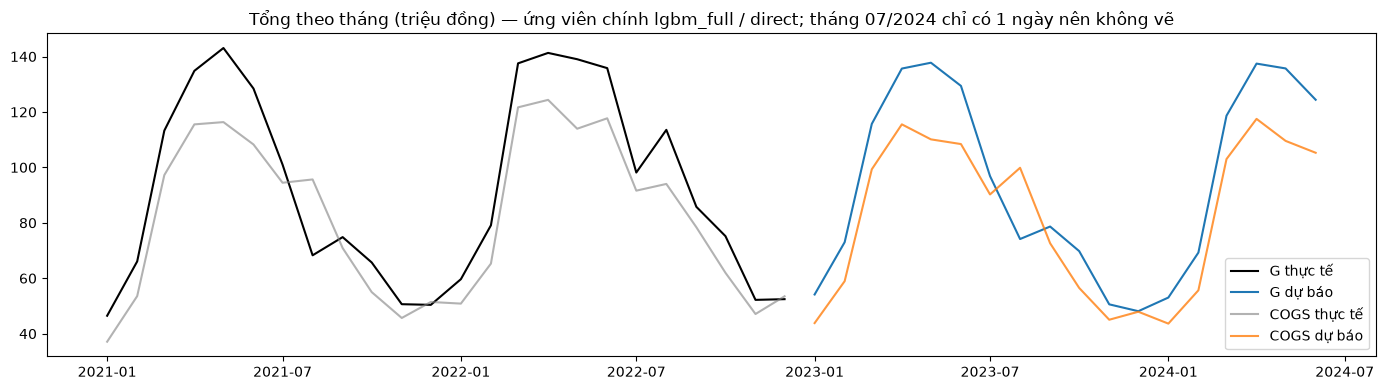

In [20]:
hist = sales.loc['2021-01-01':].resample('MS').sum()
fm = p[['yhat', 'cogs_yhat']].resample('MS').sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(hist.index, hist.Revenue / 1e6, color='black', label='G thực tế')
ax.plot(fm.index[:-1], fm.yhat[:-1] / 1e6, label='G dự báo')
ax.plot(hist.index, hist.COGS / 1e6, color='gray', alpha=0.6, label='COGS thực tế')
ax.plot(fm.index[:-1], fm.cogs_yhat[:-1] / 1e6, alpha=0.8, label='COGS dự báo')
ax.set_title(f'Tổng theo tháng (triệu đồng) — ứng viên chính {PRIMARY[0]} / {PRIMARY[1]}; tháng 07/2024 chỉ có 1 ngày nên không vẽ')
ax.legend(); plt.tight_layout(); plt.show()

In [21]:
print('Tổng thời gian chạy notebook: %.0f giây' % (time.time() - T_START))

Tổng thời gian chạy notebook: 324 giây


## 8.1. Phân rã model LightGBM chính (B4a)

Cùng `Forecaster` đã fit ở §8, lấy `pred_contrib=True` từ LightGBM. Giá trị gốc và các đóng góp cộng trên **log(G)**; trên thang tiền, từng đóng góp là hệ số nhân `exp(đóng góp log)`, không phải số VND cộng được. Nhóm biến gồm mùa vụ, đầu/cuối tháng, từng đợt khuyến mãi, chế độ sau 2018 và năm chẵn/lẻ. Đây là **phân rã model, không phải nguyên nhân**. Cell dưới là bằng chứng chạy lại được; chưa coi là kết quả đã chạy cho tới khi PM chạy hết notebook và lưu output.


In [22]:
from scripts.forecast import stage as forecast_stage
explain = forecast_stage.explain_table({'primary': PRIMARY, 'final': final, 'forecaster': fc}, 'notebook', forecast_stage.model_version())
primary_daily = final[final.is_primary].set_index('forecast_date')
check = explain.groupby('forecast_date').agg(base_log=('base_log', 'first'), total_log=('contribution_log', 'sum'), forecast_log=('forecast_log', 'first'))
check['yhat'] = primary_daily.loc[check.index, 'yhat'].values
check['abs_error_log'] = (check.base_log + check.total_log - np.log(check.yhat)).abs()
assert len(check) == F.H and check.abs_error_log.max() < 1e-7
assert np.allclose(np.exp(check.forecast_log), check.yhat, rtol=1e-10, atol=1e-6)
print('Số ngày:', len(check), '| số nhóm:', explain.feature_group.nunique(), '| lệch log lớn nhất:', check.abs_error_log.max())
display(explain[explain.forecast_date == dates[0].date()][['feature_group', 'base_log', 'contribution_log', 'multiplier', 'forecast_log']])

Số ngày: 548 | số nhóm: 10 | lệch log lớn nhất: 4.796163466380676e-14


,feature_group,base_log,contribution_log,multiplier,forecast_log
0,che_do_sau_2018,15.102577,-0.409475,0.663999,14.46997
548,dau_cuoi_thang,15.102577,0.267737,1.307003,14.46997
1096,mua_vu,15.102577,-0.411448,0.662690,14.46997
1644,nam_chan_le,15.102577,-0.034104,0.966471,14.46997
2192,promo_fall_launch,15.102577,-0.000060,0.999940,14.46997
2740,promo_mid_year_sale,15.102577,0.002739,1.002743,14.46997
3288,promo_rural_special,15.102577,-0.000438,0.999562,14.46997
3836,promo_spring_sale,15.102577,0.000369,1.000369,14.46997
4384,promo_urban_blowout,15.102577,0.007085,1.007110,14.46997
4932,promo_year_end_sale,15.102577,-0.055012,0.946474,14.46997



## 9. Tóm tắt cho PM

- **Ứng viên được dùng:** LightGBM trên toàn chuỗi, COGS dự báo trực tiếp (`lgbm_full / direct`). Luật §3 tự chọn, không ai chọn tay.
- **Hơn mốc bao nhiêu:** điểm ngày kết hợp thấp hơn seasonal naive 2 năm khoảng 20% (§6). Đây là sai số backtest 2020–2022, không phải độ chính xác trên 2023–2024, và hơi lạc quan.
- **Tháng 8/2023:** G dự báo thấp hơn tháng 8/2022, COGS/G > 1 (§8). Đạt kiểm của hợp đồng.
- **File nộp:** `data/submission_b2.csv` (không commit).
- **Việc kế tiếp:** sửa test COGS/G ở hợp đồng §9 theo cell §8; đưa luật chọn vào stage pipeline (B2b).
